# Traffic Sign Visibility Audit
**Course:** CSC 605 Advanced AI Programming | **Student:** Salihu Umar Ibrahim | **ID:** 481009445

This notebook runs from the first cell to the last and rebuilds every table and figure from the raw annotation file in `data/`.

## 1. Case framing and dataset

**Case.** A road-safety analytics team cannot inspect every traffic-sign photograph by hand. In this audit I measure simple image properties and build a transparent, rule-based *review-priority* flag.

**Central question.** *Which images should be reviewed first, and what evidence supports that priority?*

**Dataset.** German Traffic Sign Recognition Benchmark (GTSRB), Real-Time Computer Vision Group, Ruhr-Universität Bochum. Official page: https://benchmark.ini.rub.de/gtsrb_dataset.html. Archival copy used: https://zenodo.org/records/13741936. The dataset is not included in this repository; the README states where it is placed in `data/`.

**Scope.** I use the labeled **training** images and their supplied annotations (`Train.csv`, `signnames.csv`). Class counts use *all* annotation rows. Image measurements use a seeded, stratified **sample** (at most 500 images per selected class). I keep the two separate throughout.

**Wording rules I follow in this project.**
- Every cutoff is a *project-specific triage setting*, not a road-safety standard.
- A review flag is a triage aid, not a safety verdict and not proof that a sign is unsafe or misclassified.
- Sharpness (variance of the Laplacian) is a proxy, not a human readability score.
- Associations are described without claiming causation.
- The supplied class labels are used as given; no label is inferred from colour.

## 2. Setup

In [35]:
import sys
from pathlib import Path

import cv2
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Find the project folder (the one that contains requirements.txt); no personal paths are used.
ROOT = Path.cwd().resolve()
while not (ROOT / "requirements.txt").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("requirements.txt was not found above the notebook; the notebook must sit inside the project folder.")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from traffic_audit import (
    FEATURE_COLUMNS, TrafficSignAudit, assign_review_priority,
    extract_image_features, load_annotations, validate_annotations,
)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

SEED = 42          # random seed for the stratified sample (reported in the README and report)
N_CLASSES = 8      # number of sign classes analysed (the project requires at least 5)
PER_CLASS = 500    # at most this many images per class

audit = TrafficSignAudit(ROOT / "data", ROOT / "outputs", n_classes=N_CLASSES, per_class=PER_CLASS, seed=SEED)
print("Project folder:", ROOT.name)
print("numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__, "| opencv", cv2.__version__)

Project folder: Project
numpy 2.5.5 | pandas 3.1.1 | matplotlib 3.11.2 | opencv 5.1.0


## 3. Inspect and prepare the data (Part 2)

### 3.1 Load the annotations
`Train.csv` has one row per training image: image size, region of interest (ROI), class ID and image path.
The stored paths start with `/code/` (the dataset author's folder). The loader removes that prefix and builds each path **relative to `data/`**, so no personal absolute path is used.

In [36]:
annotations = audit.load_annotations()
print(f"Annotation rows (images): {len(annotations):,}")
annotations.head()

Annotation rows (images): 39,209


,ann_row,width,height,x1,y1,x2,y2,class_id,path,raw_path,image_path,class_name
0,0,27,26,5,5,22,20,20,/code/Train/20/00020_00000_00000.png,/code/Train/20/00020_00000_00000.png,Train/20/00020_00000_00000.png,Dangerous curve to the right
1,1,28,27,5,6,23,22,20,/code/Train/20/00020_00000_00001.png,/code/Train/20/00020_00000_00001.png,Train/20/00020_00000_00001.png,Dangerous curve to the right
2,2,29,26,6,5,24,21,20,/code/Train/20/00020_00000_00002.png,/code/Train/20/00020_00000_00002.png,Train/20/00020_00000_00002.png,Dangerous curve to the right
3,3,28,27,5,6,23,22,20,/code/Train/20/00020_00000_00003.png,/code/Train/20/00020_00000_00003.png,Train/20/00020_00000_00003.png,Dangerous curve to the right
4,4,28,26,5,5,23,21,20,/code/Train/20/00020_00000_00004.png,/code/Train/20/00020_00000_00004.png,Train/20/00020_00000_00004.png,Dangerous curve to the right


In [37]:
# Data types and missing values in the raw annotation fields
print(annotations[["width", "height", "x1", "y1", "x2", "y2", "class_id", "image_path"]].dtypes)
print("\nMissing values per column:")
print(annotations.isna().sum())

width         int64
height        int64
x1            int64
y1            int64
x2            int64
y2            int64
class_id      int64
image_path      str
dtype: object

Missing values per column:
ann_row       0
width         0
height        0
x1            0
y1            0
x2            0
y2            0
class_id      0
path          0
raw_path      0
image_path    0
class_name    0
dtype: int64


### 3.2 Validate every row (nothing is dropped silently)
Each row receives validation flags. A row is **excluded from the analysis** only for one of these reasons: a missing or malformed number, a non-positive width or height, an invalid class ID, an image file that does not exist, or a repeated image path. An **invalid or absent ROI does not exclude the image**: the full image is still measured and only the crop measurements are set to `NaN`. ROI coordinates are treated as inclusive pixel indices, so a valid box satisfies `0 <= x1 <= x2 <= width-1` and `0 <= y1 <= y2 <= height-1`.

In [38]:
checks = audit.validate()
checks

,check,rows_affected,action
0,Rows in annotation file,39209,all rows kept in the validated table
1,Distinct class IDs,43,reported
2,Missing or malformed numeric fields,0,excluded
3,Width or height not positive,0,excluded
4,Invalid class ID,0,excluded
5,Image file not found,0,excluded
6,Duplicate annotation rows (identical),0,later copies excluded
7,Duplicate image paths (later copies),0,excluded
8,Invalid or absent ROI,0,kept; ROI measures set to NaN
9,Rows usable for analysis,39209,-


In [39]:
# Every excluded row with its reason (the same table is saved to outputs/processed/exclusion_log.csv)
print(f"Excluded rows: {len(audit.exclusion_log)}")
audit.exclusion_log.head(20)

Excluded rows: 0


,ann_row,image_path,class_id,exclude_reason


**Finding.** All 39,209 annotation rows passed validation: there are no missing or malformed values, no invalid class IDs, no missing image files, no duplicate rows or paths, and no invalid ROI boxes. The exclusion log is therefore empty and no record was dropped. The checks stay in the code so that they still protect a different copy of the data.

### 3.3 Full-dataset counts (all annotation rows, before any sampling)

In [40]:
q1_full = audit.validated.dropna(subset=["class_id"]).groupby(["class_id", "class_name"]).size().rename("annotation_rows").reset_index()
print(f"Full dataset: {len(audit.validated):,} images in {audit.validated['class_id'].nunique()} classes")
q1_full.sort_values("annotation_rows", ascending=False).reset_index(drop=True)

Full dataset: 39,209 images in 43 classes


,class_id,class_name,annotation_rows
0,2,Speed limit (50km/h),2250
1,1,Speed limit (30km/h),2220
2,13,Yield,2160
3,12,Priority road,2100
4,38,Keep right,2070
5,10,No passing for vehicles over 3.5 metric tons,2010
6,4,Speed limit (70km/h),1980
7,5,Speed limit (80km/h),1860
8,25,Road work,1500
9,9,No passing,1470


## 4. Choose a reproducible sample
I choose the classes by a fixed rule, not by hand: I sort all usable classes by image count and take **eight classes at evenly spaced ranks**, so the selection spans the whole range from small to large classes. From each selected class I draw at most 500 images at random with seed 42. The same settings always reproduce the same sample.

In [41]:
sample = audit.select_sample()
print("Selected class IDs:", audit.classes)
print(f"Sampled images: {len(sample):,}  (seed = {SEED}, at most {PER_CLASS} per class)")
sample.groupby(["class_id", "class_name"]).size().rename("sampled_images").reset_index()

Selected class IDs: [0, 2, 3, 4, 14, 30, 40, 42]
Sampled images: 3,260  (seed = 42, at most 500 per class)


,class_id,class_name,sampled_images
0,0,Speed limit (20km/h),210
1,2,Speed limit (50km/h),500
2,3,Speed limit (60km/h),500
3,4,Speed limit (70km/h),500
4,14,Stop,500
5,30,Beware of ice/snow,450
6,40,Roundabout mandatory,360
7,42,End of no passing by vehicles over 3.5 metric ...,240


## 5. Extract visual measurements with OpenCV (Part 3)
I read each image with `cv2.imread`. If a read fails, the image is logged in `audit.skipped` with the reason and the loop continues. OpenCV loads colour images in **BGR** order; I convert to **RGB** only for display with Matplotlib.

| Feature | Definition | Unit |
|---|---|---|
| `brightness` | mean of the grayscale pixel values | intensity, 0-255 |
| `contrast` | standard deviation of the grayscale pixel values | intensity units |
| `sharpness` | variance of `cv2.Laplacian(gray, cv2.CV_64F)`; a proxy for sharpness, **not** a human readability score | squared intensity units |
| `img_width`, `img_height` | size of the image that was actually loaded | pixels |
| `aspect_ratio` | `img_width / img_height` | ratio |
| `min_side` | the shorter side of the image | pixels |
| `roi_brightness`, `roi_contrast`, `roi_sharpness` | the same three measures computed on the annotated ROI crop | as above |

In [42]:
features = audit.extract_features()
print(f"Images measured: {len(features):,} | skipped: {len(audit.skipped)}")
print(f"Image size differs from the annotated size in {int((~features['size_matches']).sum())} images")
features.head()

Images measured: 3,260 | skipped: 0
Image size differs from the annotated size in 0 images


,ann_row,image_path,class_id,class_name,width,height,x1,y1,x2,y2,roi_valid,track_id,brightness,contrast,sharpness,img_width,img_height,aspect_ratio,min_side,roi_brightness,roi_contrast,roi_sharpness,size_matches
0,360,Train/0/00000_00000_00000.png,0,Speed limit (20km/h),29,30,5,6,24,25,True,00000_00000,127.378161,45.603849,4623.091140,29,30,0.966667,29,132.340000,41.886685,6126.723400,True
1,361,Train/0/00000_00000_00001.png,0,Speed limit (20km/h),30,30,5,5,25,25,True,00000_00000,128.307778,45.720719,5136.776310,30,30,1.000000,30,132.829932,41.870501,7267.333837,True
2,362,Train/0/00000_00000_00002.png,0,Speed limit (20km/h),30,30,5,5,25,25,True,00000_00000,126.656667,44.542700,4411.520217,30,30,1.000000,30,132.290249,41.449170,6180.184933,True
3,363,Train/0/00000_00000_00003.png,0,Speed limit (20km/h),31,31,5,5,26,26,True,00000_00000,125.161290,45.182368,5041.459462,31,31,1.000000,31,131.493802,42.910078,6699.040174,True
4,364,Train/0/00000_00000_00004.png,0,Speed limit (20km/h),30,32,5,6,25,26,True,00000_00000,129.823958,47.292103,5492.097760,30,32,0.937500,30,134.866213,44.079065,7575.681522,True


In [43]:
# Images that could not be read (empty means every sampled image loaded correctly)
audit.skipped

,ann_row,image_path,reason


## 6. Review-priority rule (Part 4)
My rule uses percentile cutoffs computed on the analysis sample. An image earns one point for each condition it meets:

| Condition | Meaning | Test |
|---|---|---|
| `dark` | unusually dark | brightness below the **low** percentile |
| `overexposed` | unusually bright | brightness above the **high** percentile |
| `low_contrast` | little tonal variation | contrast below the low percentile |
| `blurry` | low edge response | sharpness below the low percentile |
| `small` | few pixels | shorter side below the low percentile |

`review_score` is the number of points. **Score 1 = medium priority, score 2 or more = high priority.** Images are reviewed in order of score, then by lowest sharpness. The base rule uses the 10th and 90th percentiles; the sensitivity check repeats the rule with the 5th/95th (*strict*) and 20th/80th (*loose*) percentiles. These are project-specific triage settings, not safety standards.

In [44]:
# NumPy evidence: percentile cutoffs, a vectorised mask and np.select (no row-by-row loops)
brightness = audit.features["brightness"].to_numpy()
p10, p90 = np.percentile(brightness, [10, 90])           # percentile cutoffs
too_dark = brightness < p10                              # vectorised boolean mask
too_bright = brightness > p90
band = np.select([too_dark, too_bright], ["dark", "overexposed"], default="normal")  # np.select
print(f"10th percentile = {p10:.1f}, 90th percentile = {p90:.1f}")
print(f"dark: {too_dark.sum()} images, overexposed: {too_bright.sum()} images, normal: {(band == 'normal').sum()} images")

10th percentile = 27.9, 90th percentile = 150.6
dark: 326 images, overexposed: 326 images, normal: 2608 images


In [45]:
flagged = audit.flag()
cut = pd.Series(audit.cutoffs, name="base cutoff").round(2)
print("Base-rule cutoffs (project-specific triage settings):")
print(cut.to_string())
print(f"\nFlagged overall: {int(flagged['review_flag'].sum()):,} of {len(flagged):,} images "
      f"({100 * flagged['review_flag'].mean():.1f}%)")
flagged["review_tier"].value_counts().rename("images").to_frame()

Base-rule cutoffs (project-specific triage settings):
dark             27.94
overexposed     150.58
low_contrast     11.81
blurry          130.67
small            30.00

Flagged overall: 1,042 of 3,260 images (32.0%)


,images
review_tier,
none,2218
medium,701
high,341


In [46]:
# How many images does each condition catch, and which is the primary reason?
conditions = flagged[[c for c in flagged.columns if c.startswith("flag_")]].sum().rename("images").to_frame()
conditions["pct_of_sample"] = (100 * conditions["images"] / len(flagged)).round(1)
conditions

,images,pct_of_sample
flag_dark,326,10.0
flag_overexposed,326,10.0
flag_low_contrast,326,10.0
flag_blurry,326,10.0
flag_small,311,9.5


In [47]:
# The single reason shown first for each flagged image (priority order: blurry, low_contrast, dark, overexposed, small)
flagged["primary_reason"].value_counts().rename("images").to_frame()

,images
primary_reason,
none,2218
blurry,326
overexposed,326
small,236
low_contrast,93
dark,61


In [48]:
# Sensitivity check: the same rule with two alternative cutoff settings
audit.sensitivity_table()

,setting,low_pct,high_pct,cut_dark,cut_overexposed,cut_low_contrast,cut_blurry,cut_small,n_images,n_flagged,pct_flagged
0,strict,5,95,20.30,172.36,8.08,76.71,28.0,3260,496,15.21
1,base,10,90,27.94,150.58,11.81,130.67,30.0,3260,1042,31.96
2,loose,20,80,40.13,127.41,18.96,261.52,32.0,3260,1879,57.64


**Finding.** With the base cutoffs (dark below 27.9, overexposed above 150.6, low contrast below 11.8, blurry below 130.7, small below 30 pixels) I flag 1,042 of the 3,260 sampled images (32.0%): 701 as medium priority and 341 as high priority. Each of the dark, overexposed, low-contrast and blurry conditions catches 326 images (10.0%) by construction, and the small condition catches 311 (9.5%). The conditions overlap strongly: 252 of the 326 dark images are also low in contrast. The strict setting flags 496 images (15.2%) and the loose setting 1,879 (57.6%), so the overall flag rate depends heavily on the percentiles I choose. All cutoffs are project-specific triage settings.

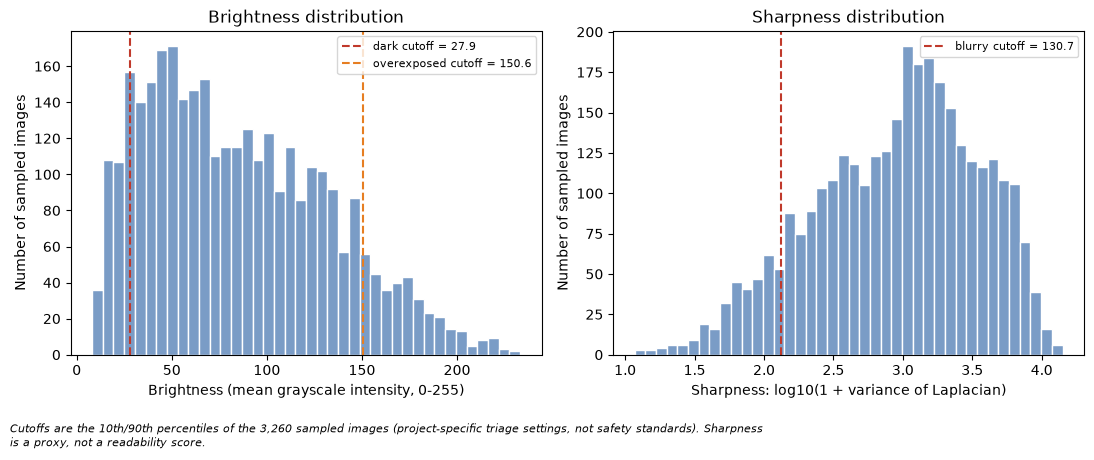

In [49]:
audit.fig_distributions();

In [50]:
# Comparison of full-image and ROI-crop measurements
audit.roi_comparison()

,measure,n_images,mean_full,mean_roi_crop,mean_difference,spearman_full_vs_crop
0,brightness,3260,84.60,85.81,1.22,0.947
1,contrast,3260,44.28,41.10,-3.18,0.966
2,sharpness,3260,1847.09,2519.21,672.12,0.968


**Finding.** The crop and the full image agree closely in rank (Spearman rho = 0.95 for brightness, 0.97 for contrast and 0.97 for sharpness). The crop has a higher mean sharpness (2,519 against 1,847) and a lower mean contrast (41.1 against 44.3), which is expected because it leaves out most of the soft background. I use the full image for the review rule, because it gives one value per file and does not depend on the quality of the annotated box, and the ranking of images is almost the same.

## 7. Analyse and visualise (Part 5)
Each question below uses a pandas `groupby` summary and at least one Matplotlib figure. Figures are saved to `outputs/figures/` and carry their own caption.

### Q1. Which selected classes have the largest and smallest image counts? How does imbalance matter?

In [51]:
q1 = audit.q1_class_counts()
selected = q1[q1["selected"]].sort_values("usable_rows", ascending=False).reset_index(drop=True)
big, small = selected.iloc[0], selected.iloc[-1]
print(f"Largest selected class : {int(big.class_id)} {big.class_name} ({int(big.usable_rows):,} usable images, {int(big.sampled_images)} sampled)")
print(f"Smallest selected class: {int(small.class_id)} {small.class_name} ({int(small.usable_rows):,} usable images, {int(small.sampled_images)} sampled)")
print(f"Size ratio largest/smallest in the full data: {big.usable_rows / small.usable_rows:.1f} : 1")
print(f"Size ratio largest/smallest in the sample    : {selected.sampled_images.max() / selected.sampled_images.min():.1f} : 1")
selected

Largest selected class : 2 Speed limit (50km/h) (2,250 usable images, 500 sampled)
Smallest selected class: 0 Speed limit (20km/h) (210 usable images, 210 sampled)
Size ratio largest/smallest in the full data: 10.7 : 1
Size ratio largest/smallest in the sample    : 2.4 : 1


,class_id,class_name,annotation_rows,usable_rows,sampled_images,selected
0,2,Speed limit (50km/h),2250,2250,500,True
1,4,Speed limit (70km/h),1980,1980,500,True
2,3,Speed limit (60km/h),1410,1410,500,True
3,14,Stop,780,780,500,True
4,30,Beware of ice/snow,450,450,450,True
5,40,Roundabout mandatory,360,360,360,True
6,42,End of no passing by vehicles over 3.5 metric ...,240,240,240,True
7,0,Speed limit (20km/h),210,210,210,True


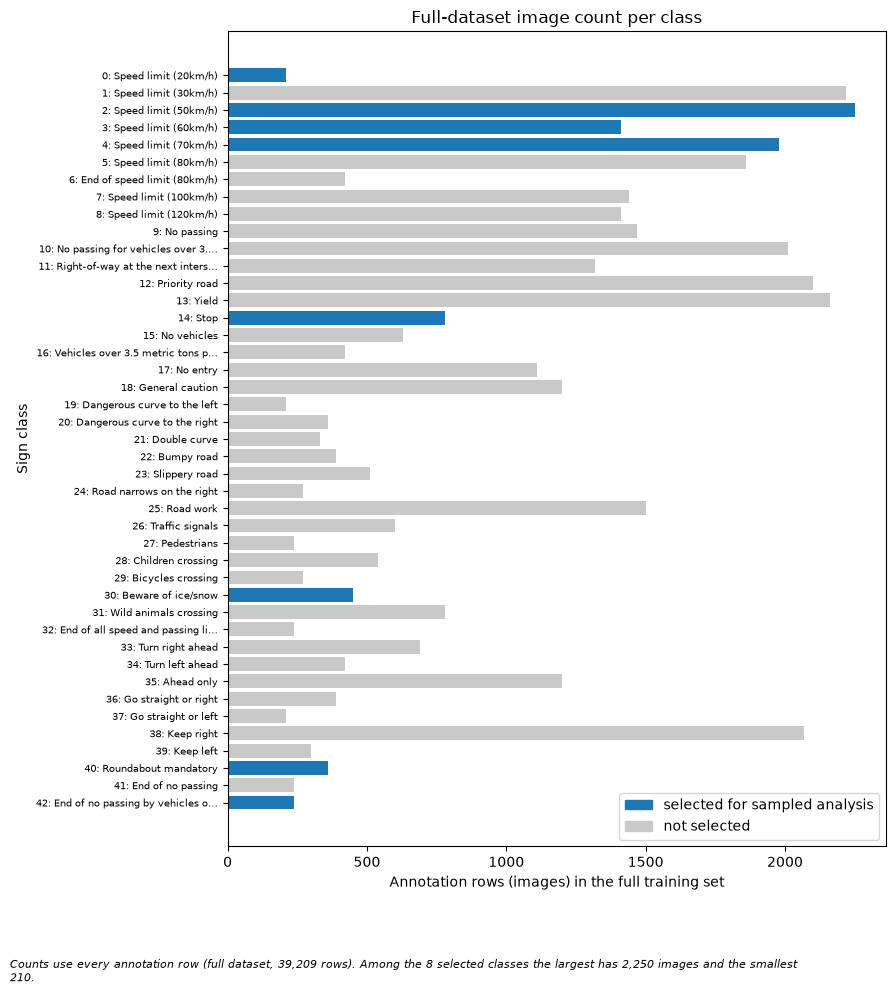

In [52]:
audit.fig_class_counts();

**Finding.** The full training set has 39,209 images in 43 classes, from 210 to 2,250 images per class. Among my eight selected classes the largest is class 2, Speed limit (50km/h), with 2,250 images and the smallest is class 0, Speed limit (20km/h), with 210 images, a ratio of about 10.7 to 1. The cap of 500 images per class reduces the ratio to 2.4 to 1 in the sample (500 against 210), but it does not make the classes equivalent: classes 0, 42, 40 and 30 contain only 7, 8, 12 and 15 physical signs (tracks), against 75 for class 2 (see the track table below). Percentages for the small classes therefore rest on few physical signs, and I compare them with caution. Four classes (2, 3, 4 and 14) supply 2,000 of the 3,260 sampled images (61%), so the pooled percentile cutoffs follow these classes more closely than the others.

### Q2. How do image size, brightness, contrast and sharpness differ across classes?

In [53]:
q2 = audit.q2_class_profiles()
print("*_effect = (class median - overall median) / overall IQR. |effect| >= 0.5 is marked 'notable' (a project rule of thumb).")
q2.round(2)

*_effect = (class median - overall median) / overall IQR. |effect| >= 0.5 is marked 'notable' (a project rule of thumb).


,class_id,class_name,n,median_min_side,median_brightness,median_contrast,median_sharpness,min_side_effect,brightness_effect,contrast_effect,sharpness_effect,notable
0,0,Speed limit (20km/h),210,45.0,122.60,51.09,1668.88,0.09,0.62,0.22,0.29,True
1,2,Speed limit (50km/h),500,39.0,87.30,47.84,1707.91,-0.17,0.13,0.14,0.31,False
2,3,Speed limit (60km/h),500,39.0,51.46,30.02,697.02,-0.17,-0.35,-0.28,-0.17,False
3,4,Speed limit (70km/h),500,38.5,61.14,34.80,711.88,-0.20,-0.22,-0.17,-0.16,False
4,14,Stop,500,55.0,107.33,60.02,1713.14,0.52,0.41,0.43,0.32,True
5,30,Beware of ice/snow,450,43.0,60.51,34.46,390.64,0.00,-0.23,-0.18,-0.31,False
6,40,Roundabout mandatory,360,49.5,90.72,55.36,1230.37,0.28,0.18,0.32,0.09,False
7,42,End of no passing by vehicles over 3.5 metric ...,240,37.0,37.95,19.77,208.78,-0.26,-0.54,-0.52,-0.40,True


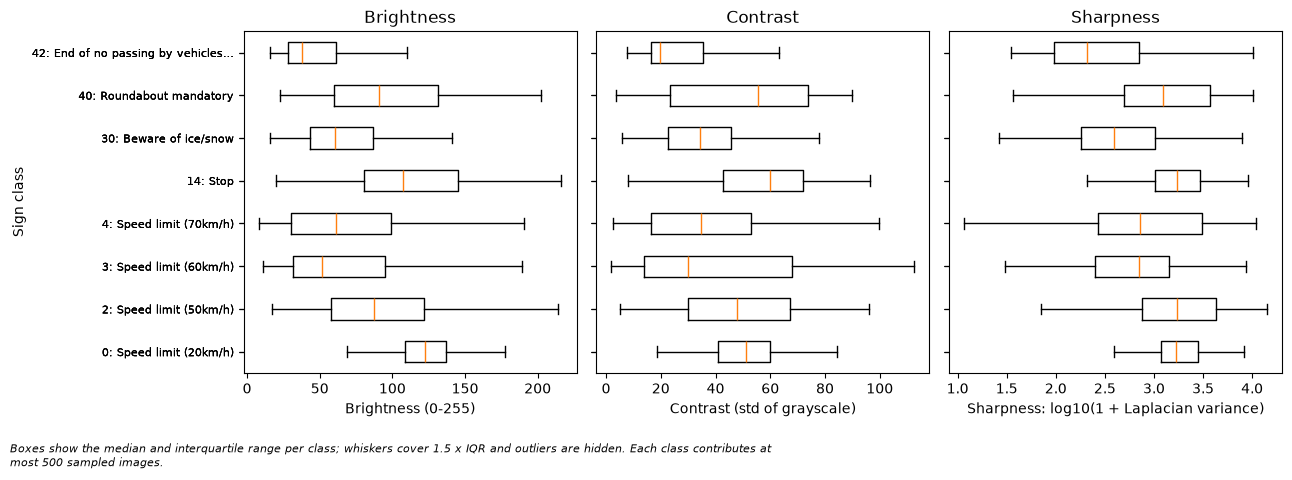

In [54]:
audit.fig_boxplots();

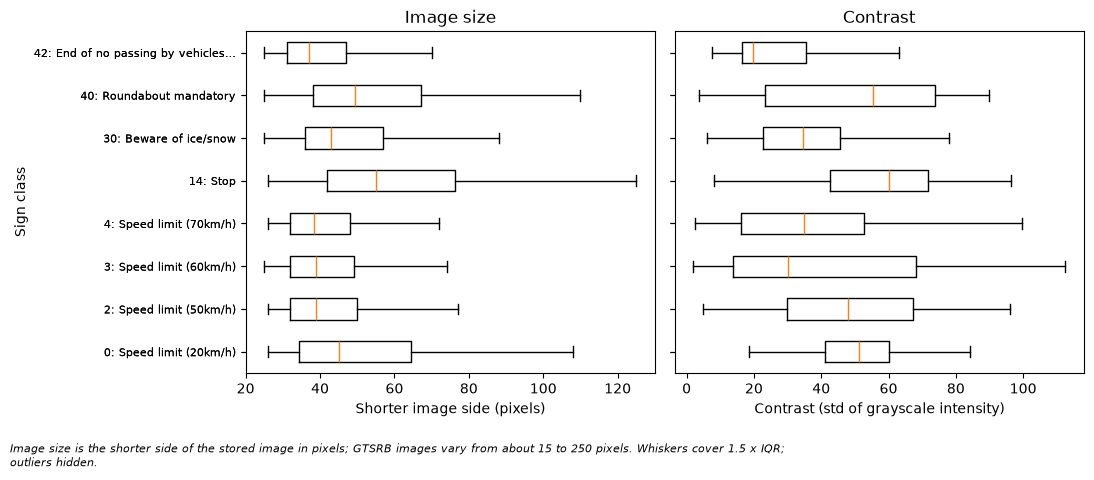

In [55]:
audit.fig_size_contrast();

**Finding.** The classes differ mostly in how dark and how low in contrast their images are. Class 42 (End of no passing by vehicles over 3.5 metric tons) has the lowest median brightness (38.0, against 77.4 for the whole sample), contrast (19.8, against 41.9) and sharpness (209, against 1,048), and the smallest median size (37 pixels, against 43). Classes 3, 4 and 30 are also darker than average (median brightness 51, 61 and 61). Class 0 is the brightest (median 123), and class 14 (Stop) has the largest images (median shorter side 55 pixels) and the highest contrast (60). With the effect measure above, only classes 0, 14 and 42 reach |effect| of 0.5. Only class 42 differs in the direction that raises review priority (brightness effect -0.54, contrast effect -0.52); classes 0 and 14 differ in the direction that lowers it. These differences describe the sampled images and do not explain why they arise.

### Q3. What percentage of images is flagged in each class? Does the ranking change with the alternative cutoffs?

In [56]:
q3 = audit.q3_flag_rates()
q3.round(1)

,class_id,class_name,pct_flagged_strict,pct_flagged_base,pct_flagged_loose,rank_strict,rank_base,rank_loose,pct_high_tier_base
0,0,Speed limit (20km/h),11.4,24.3,49.5,6.0,7.0,7.0,0.0
1,2,Speed limit (50km/h),10.4,30.4,55.6,7.0,4.0,5.0,6.0
2,3,Speed limit (60km/h),16.2,40.0,60.6,3.0,3.0,3.0,19.0
3,4,Speed limit (70km/h),23.0,40.4,64.0,2.0,2.0,2.0,19.0
4,14,Stop,9.6,27.0,45.0,8.0,5.0,8.0,1.2
5,30,Beware of ice/snow,14.2,25.6,54.0,4.0,6.0,6.0,6.2
6,40,Roundabout mandatory,12.5,21.9,57.2,5.0,8.0,4.0,6.9
7,42,End of no passing by vehicles over 3.5 metric ...,27.9,45.0,83.3,1.0,1.0,1.0,25.8


In [57]:
# Does the class ranking agree between settings? (Spearman correlation of class ranks vs the base rule)
audit.rank_agreement()

,setting,spearman_rank_vs_base,top3_classes
0,strict,0.619,"42, 4, 3"
1,base,1.000,"42, 4, 3"
2,loose,0.690,"42, 4, 3"


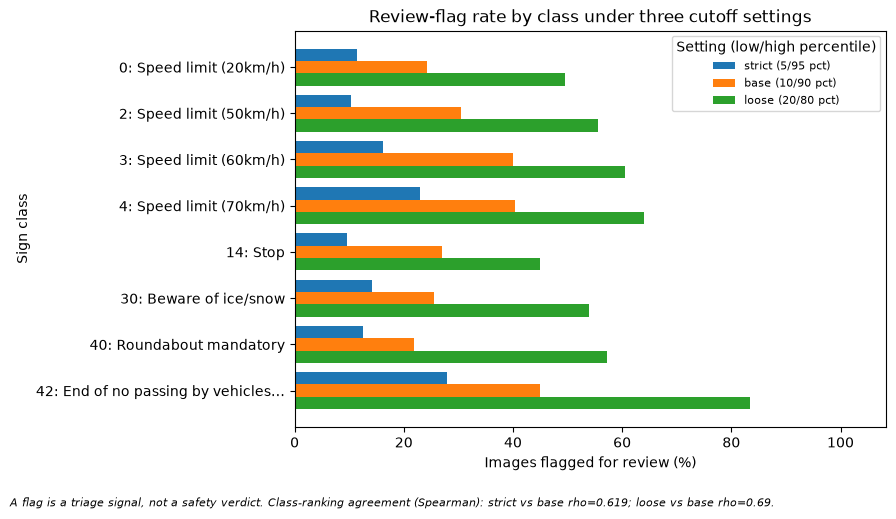

In [58]:
audit.fig_flag_rate();

**Finding.** By class, the base-rule flag rate is highest for class 42 (45.0%), class 4 (40.4%) and class 3 (40.0%), and lowest for class 40 (21.9%) and class 0 (24.3%). The share of high-priority images is 25.8% for class 42, 19.0% for classes 3 and 4, and at most 6.9% for the other classes. The same three classes are the top three under the strict (5th/95th percentile) and loose (20th/80th percentile) settings, and class 42 is first under all three. The order of the other classes changes: the Spearman correlation between the class rankings is 0.62 for strict against base and 0.69 for loose against base. Because the overall flag rate also changes a great deal with the setting (15.2%, 32.0% and 57.6%), I use the flag rates to compare classes and not as an estimate of how many images are unreadable.

### Additional check: do flags cluster within physical signs?
GTSRB file names have the form `<class>_<track>_<frame>`. All frames of one *track* show the same physical sign, so images from one track are similar and not independent. A track is called *mostly flagged* when at least half of its sampled images are flagged under the base rule.

In [59]:
audit.track_summary()

,class_id,class_name,images,tracks,tracks_with_a_high_tier_image,pct_flagged_images_in_mostly_flagged_tracks
0,0,Speed limit (20km/h),210,7,0,54.9
1,2,Speed limit (50km/h),500,75,8,56.6
2,3,Speed limit (60km/h),500,47,18,72.5
3,4,Speed limit (70km/h),500,66,18,74.8
4,14,Stop,500,26,1,57.8
5,30,Beware of ice/snow,450,15,4,73.0
6,40,Roundabout mandatory,360,12,1,57.0
7,42,End of no passing by vehicles over 3.5 metric ...,240,8,4,67.6
8,all,All selected classes,3260,256,54,66.2


**Finding.** The 3,260 sampled images come from 256 tracks, about 13 images per physical sign on average. For all selected classes, 66.2% of the flagged images lie in tracks where at least half of the sampled frames are flagged, and all 341 high-priority images come from only 54 tracks. Flags therefore cluster by physical sign, and the number of independent observations is closer to the number of tracks than to the number of images.

### Q4. Do images with lower sharpness also tend to have lower contrast or brightness?

In [60]:
overall, by_class = audit.q4_associations()
print("Spearman rank correlations across all sampled images:")
overall

Spearman rank correlations across all sampled images:


,sharpness,contrast,brightness,min_side
sharpness,1.000,0.731,0.751,-0.091
contrast,0.731,1.000,0.857,0.267
brightness,0.751,0.857,1.000,0.203
min_side,-0.091,0.267,0.203,1.000


In [61]:
# The same sharpness-contrast and sharpness-brightness correlations, class by class
by_class

,class_id,class_name,n,rho_sharp_contrast,rho_sharp_brightness
0,0,Speed limit (20km/h),210,0.222,0.322
1,2,Speed limit (50km/h),500,0.721,0.666
2,3,Speed limit (60km/h),500,0.808,0.812
3,4,Speed limit (70km/h),500,0.859,0.868
4,14,Stop,500,0.335,0.402
5,30,Beware of ice/snow,450,0.517,0.608
6,40,Roundabout mandatory,360,0.621,0.590
7,42,End of no passing by vehicles over 3.5 metric ...,240,0.890,0.894


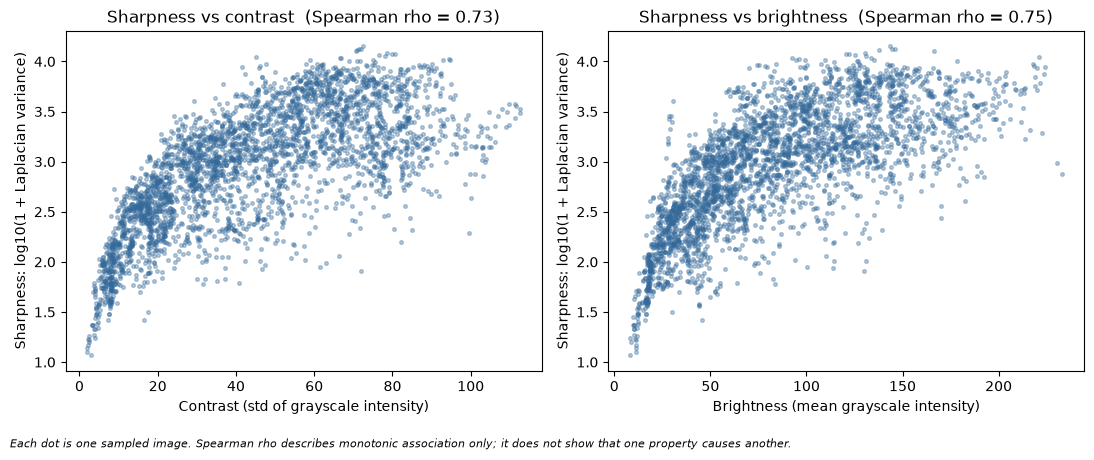

In [62]:
audit.fig_associations();

**Finding.** Across the 3,260 sampled images, lower sharpness goes together with lower contrast (Spearman rho = 0.73) and lower brightness (rho = 0.75), and contrast and brightness are strongly related to each other (rho = 0.86). The association with image size is close to zero (rho = -0.09). By class, the sharpness-contrast association is strong for classes 42, 4 and 3 (rho = 0.89, 0.86 and 0.81) and weak for classes 0 and 14 (rho = 0.22 and 0.34). These are associations within this sample and do not show that darkness or low contrast cause low sharpness scores. Part of the association comes from how the measure is built: the variance of the Laplacian grows with the square of the intensity range, so a dark, low-contrast image scores low even when it is in focus. The sharpness flag is therefore partly a darkness flag, which fits the overlap in the data: 209 of the 326 blurry images are also dark, and 233 are also low in contrast.

### Q5. Which three images best illustrate the rule?

In [63]:
audit.examples[["image_path", "class_id", "class_name", "primary_reason", "brightness", "contrast", "sharpness", "min_side"]].round(1)

,image_path,class_id,class_name,primary_reason,brightness,contrast,sharpness,min_side
0,Train/4/00004_00054_00022.png,4,Speed limit (70km/h),blurry,8.0,2.9,10.7,74
1,Train/30/00030_00009_00028.png,30,Beware of ice/snow,blurry,45.8,16.5,25.1,131
2,Train/2/00002_00015_00029.png,2,Speed limit (50km/h),overexposed,233.2,41.5,758.2,124


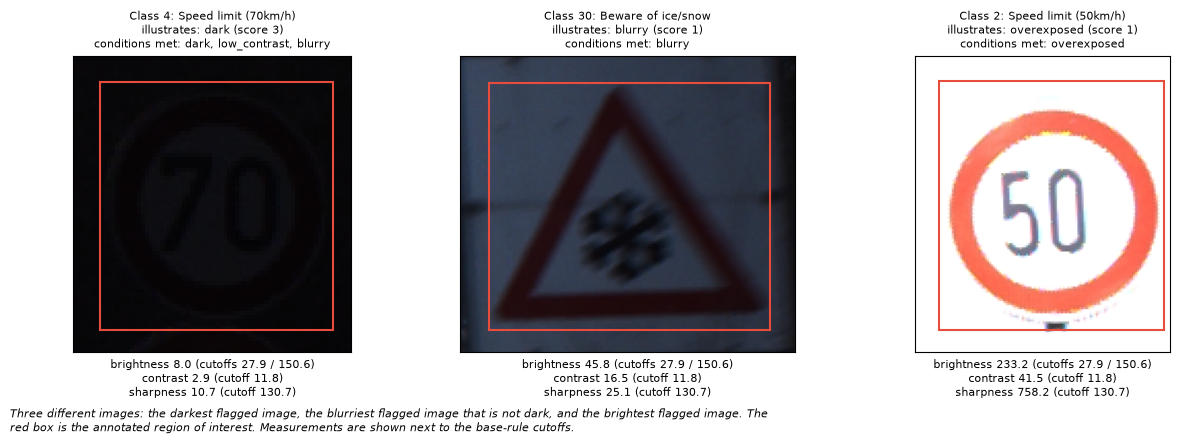

In [64]:
audit.fig_examples();

**Finding.** Figure 8 shows three different files. (1) Class 4, Speed limit (70km/h), meets three conditions (dark, low contrast, blurry) with brightness 8.0, contrast 2.9 and sharpness 10.7; the sign can barely be made out, so the flag is justified. (2) Class 30, Beware of ice/snow, is flagged only as blurry (sharpness 25.1 against a cutoff of 130.7); the triangle is recognisable, but the symbol inside it is smeared, which is what the sharpness measure is meant to catch. (3) Class 2, Speed limit (50km/h), is flagged only as overexposed (brightness 233.2 against a cutoff of 150.6), yet the sign is fully readable against a white background. I kept this third example on purpose, because it shows the main weakness of my rule.

### Contact sheet: flagged and unflagged examples
Inspecting both groups is how false alarms (flagged images that look readable) and misses (unflagged images that look poor) are found.

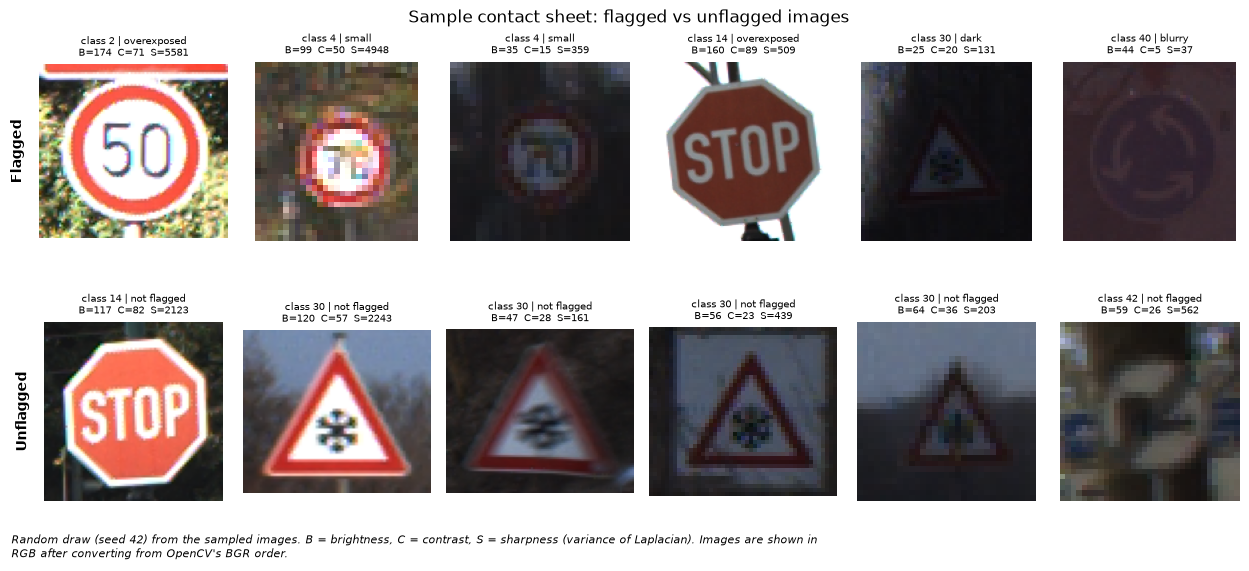

In [65]:
audit.fig_contact_sheet();

### Extra check on false alarms and possible misses
Three groups are drawn at random (seed 42): **A** images flagged only as overexposed, **B** high-priority images with a score of 3 or 4, and **C** unflagged images whose sharpness is just above the blurry cutoff.

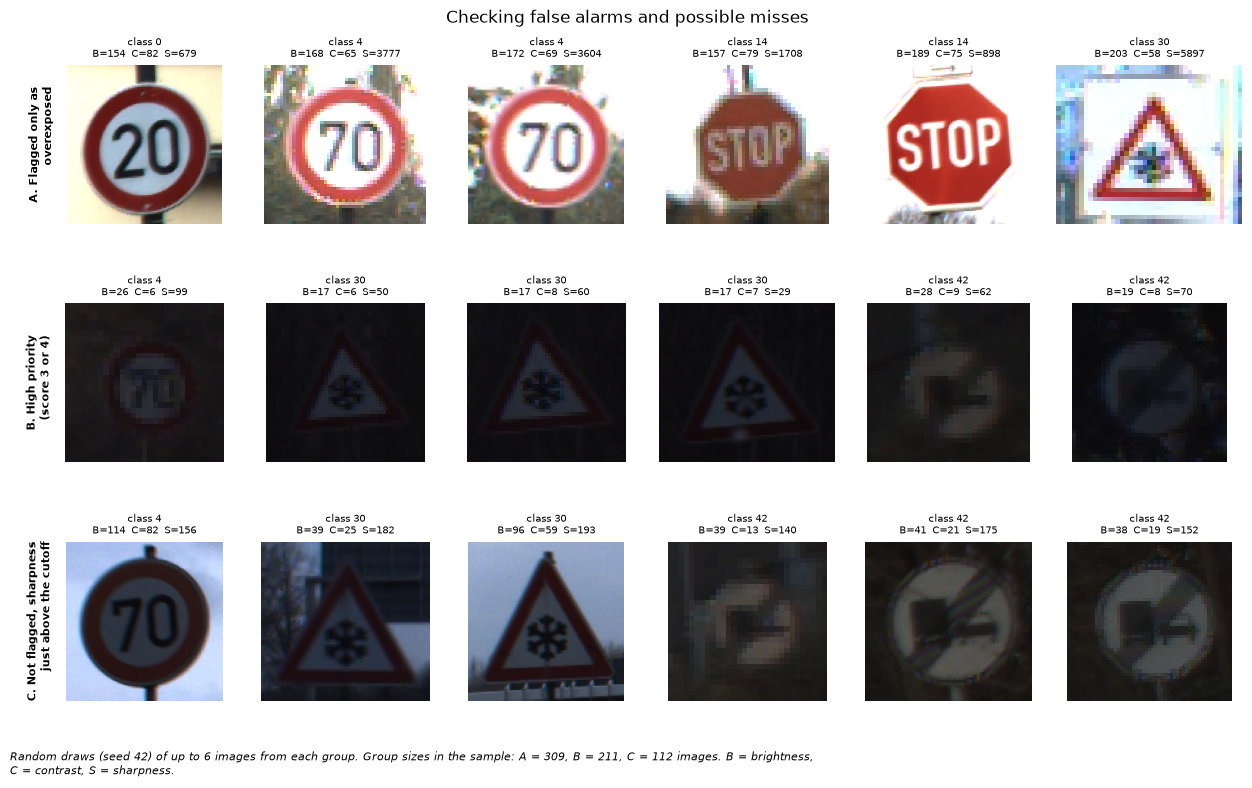

In [66]:
audit.fig_review_groups();

**False alarms.** Group A holds the 309 images flagged only as overexposed. All six images drawn at random show a clearly readable sign (class 0, two of class 4, two of class 14 and one of class 30), with high contrast (58 to 82). Brightness above the 90th percentile did not mean that the sign was hard to read, and the contact sheet (Figure 7) shows the same for two further overexposed flags, one class 2 image and one class 14 image. This condition is the main source of false alarms in my rule.

**True detections.** Group B holds the 211 images with a score of 3 or 4. All six drawn images are very dark (brightness 17 to 28) with low contrast (6 to 9), and the symbols can barely be made out. These are the images I would want a reviewer to see first.

**Possible misses.** Group C holds the 112 unflagged images whose sharpness is just above the blurry cutoff. Three of the six drawn images (one of class 4 and two of class 30) are readable. The other three (all class 42) are dark and low in detail and look little better than flagged images, but they sit just above the cutoffs (brightness 38 to 41 against a dark cutoff of 27.9; contrast 13 to 21 against 11.8). A fixed percentile cutoff treats an image just above the line very differently from one just below it, so the rule misses some images that are nearly as poor as the flagged ones. The loose setting catches more of them, at the price of flagging 57.6% of the sample. These observations come from 18 images drawn at random, so they illustrate a pattern and do not measure how often it occurs.

## 8. Recommendation and limitations (summary of the decision memo)

**Recommendation.** I recommend that reviewers work through the flagged images in three steps:
1. **High priority first** (score 2 or more): 341 images, 10.5% of the sample, from 54 physical signs. Because flags cluster by sign, one image per sign can be checked first.
2. **Medium priority next, without the overexposure-only flags:** 392 images flagged for darkness, low contrast, blur or small size alone. I did not inspect the small-size flags separately, so I treat their value as an open question.
3. **Overexposure-only flags last, or dropped:** 309 images. All six I inspected were readable.

Classes 42, 4 and 3 deserve the most attention, because they have the highest flag rates under all three settings.

**What would change the recommendation.** A manual readability check of a larger random sample from each group, ideally by two reviewers. If most overexposure-only images prove readable, I would drop that condition. If unflagged images just above the cutoffs are often unreadable, I would replace the hard cutoffs with a graded score.

**Limitations.**
- The sample covers 8 of the 43 classes, chosen by a fixed rule, and its results do not describe the other classes.
- Images from the same physical sign are not independent: the sample holds 256 tracks, and 66.2% of the flagged images lie in mostly flagged tracks.
- There is no human readability label. My readable or unreadable judgements are visual impressions of a few dozen images.
- Sharpness is a proxy that depends on brightness, contrast and image resolution, so the blurry flag partly repeats the dark and low-contrast flags.
- Percentile cutoffs describe this sample. A different sample would shift them, and four classes supply 61% of the sampled images.
- GTSRB images are German road signs photographed in a limited set of conditions and do not represent every local road environment.

## 9. Validation checks
This cell checks that: an image-read failure is caught, the feature columns exist, review flags contain only `True`/`False`, every analysed image traces back to an annotation row and a real file, no absolute path is stored, and the per-class cap is respected.

In [67]:
import tempfile

# 1. An image-read failure is caught: no exception, ok is False, and a reason is given.
missing_result = extract_image_features(ROOT / "data" / "no_such_image.png")
assert missing_result["ok"] is False and missing_result["error"], "a missing file must be reported, not raised"
with tempfile.TemporaryDirectory() as tmp:
    broken = Path(tmp) / "corrupt.png"
    broken.write_bytes(b"this is not an image")
    broken_result = extract_image_features(broken)
    assert broken_result["ok"] is False and broken_result["error"], "a corrupt file must be reported, not raised"

# 2. Output feature columns exist.
absent = [c for c in FEATURE_COLUMNS if c not in audit.flagged.columns]
assert not absent, f"missing feature columns: {absent}"

# 3. Review flags contain only True/False.
flag_columns = [c for c in audit.flagged.columns if c.startswith("flag_") or c.startswith("review_flag")]
for col in flag_columns:
    assert audit.flagged[col].dtype == bool and set(audit.flagged[col].unique()) <= {True, False}, col

# 4. Traceability: each analysed image maps to one annotation row and one real file.
assert audit.flagged["ann_row"].isin(audit.annotations["ann_row"]).all()
assert not audit.flagged["image_path"].duplicated().any()
assert all((ROOT / "data" / p).is_file() for p in audit.flagged["image_path"])

# 5. No absolute path is stored in the results.
assert not audit.flagged["image_path"].str.match(r"^(/|[A-Za-z]:)").any()

# 6. The per-class sample cap is respected and at least five classes were analysed.
assert audit.flagged.groupby("class_id").size().max() <= PER_CLASS
assert audit.flagged["class_id"].nunique() >= 5

# 7. Every measured value is finite.
assert np.isfinite(audit.flagged[["brightness", "contrast", "sharpness"]].to_numpy()).all()

print("All validation checks passed:", len(flag_columns), "flag columns,", len(FEATURE_COLUMNS), "feature columns checked.")

All validation checks passed: 9 flag columns, 7 feature columns checked.


## 10. Save the derived tables

In [68]:
saved = audit.save_tables()
for path in saved:
    print(path.relative_to(ROOT))
print("\nFigures:")
for path in sorted(audit.fig_dir.glob("*.png")):
    print(path.relative_to(ROOT))

outputs\processed\validation_checks.csv
outputs\processed\exclusion_log.csv
outputs\processed\skipped_images.csv
outputs\processed\full_dataset_class_counts.csv
outputs\processed\sample_features_tidy.csv
outputs\processed\review_priority_list.csv
outputs\processed\sensitivity_summary.csv
outputs\processed\flag_rate_by_class.csv
outputs\processed\class_profiles.csv
outputs\processed\associations_overall.csv
outputs\processed\associations_by_class.csv
outputs\processed\roi_vs_full_image.csv
outputs\processed\track_summary.csv
outputs\processed\example_images.csv

Figures:
outputs\figures\fig1_class_counts.png
outputs\figures\fig2_distributions.png
outputs\figures\fig3_class_boxplots.png
outputs\figures\fig4_flag_rate_by_class.png
outputs\figures\fig5_size_and_contrast.png
outputs\figures\fig6_sharpness_associations.png
outputs\figures\fig7_contact_sheet.png
outputs\figures\fig8_rule_examples.png
outputs\figures\fig9_review_groups.png
